# Task 1: Decision Tree Classification and Hyperparameter Tuning

## Step 1: Import libraries and configure plotting

In [1]:
import io
import json
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

plt.rcParams.update({"font.size": 9, "figure.dpi": 200})
results = {}

## Step 2: Load or generate data and fit the model

In [2]:
# Official UCI source; local fallback is only needed when offline.
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
try:
    with urlopen(url, timeout=30) as response:
        wine_csv = response.read().decode("utf-8")
except Exception:
    wine_csv = Path("../data/winequality-red.csv").read_text()
raw = np.genfromtxt(io.StringIO(wine_csv), delimiter=";", skip_header=1)
feature_names = wine_csv.splitlines()[0].replace('"', "").split(";")[:-1]
X, quality = raw[:, :-1], raw[:, -1]
y = (quality >= 6).astype(int)                      # 1 = high quality, 0 = low
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

trees = {"Default (unconstrained)": DecisionTreeClassifier(random_state=42),
         "Tuned (max_depth=3, min_samples_leaf=5)":
             DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=42)}
for name, clf in trees.items():
    clf.fit(X_tr, y_tr)
    pred = clf.predict(X_te)
    print(name, accuracy_score(y_te, pred), precision_score(y_te, pred), recall_score(y_te, pred))

Default (unconstrained) 0.753125 0.764367816091954 0.7777777777777778
Tuned (max_depth=3, min_samples_leaf=5) 0.70625 0.6878048780487804 0.8245614035087719


## Step 3: Collect the assessment results

In [3]:
t1 = {"n_samples": int(len(y)), "n_high": int(y.sum()), "n_low": int((1 - y).sum()), "trees": {}}
for name, clf in trees.items():
    pred = clf.predict(X_te)
    t1["trees"][name] = {
        "train_acc": accuracy_score(y_tr, clf.predict(X_tr)),
        "test_acc": accuracy_score(y_te, pred),
        "precision": precision_score(y_te, pred),
        "recall": recall_score(y_te, pred),
        "depth": int(clf.get_depth()),
        "leaves": int(clf.get_n_leaves()),
    }
results["task1"] = t1

## Step 4: Display key numerical results

In [4]:
print(f"Wines: {t1['n_samples']} | high: {t1['n_high']} | low: {t1['n_low']}")
for name, metrics in t1['trees'].items():
    print(name)
    print("  " + " | ".join(f"{k}: {v:g}" for k, v in metrics.items()))

Wines: 1599 | high: 855 | low: 744
Default (unconstrained)
  train_acc: 1 | test_acc: 0.753125 | precision: 0.764368 | recall: 0.777778 | depth: 18 | leaves: 209
Tuned (max_depth=3, min_samples_leaf=5)
  train_acc: 0.727912 | test_acc: 0.70625 | precision: 0.687805 | recall: 0.824561 | depth: 3 | leaves: 8


## Step 5: Show the main figure

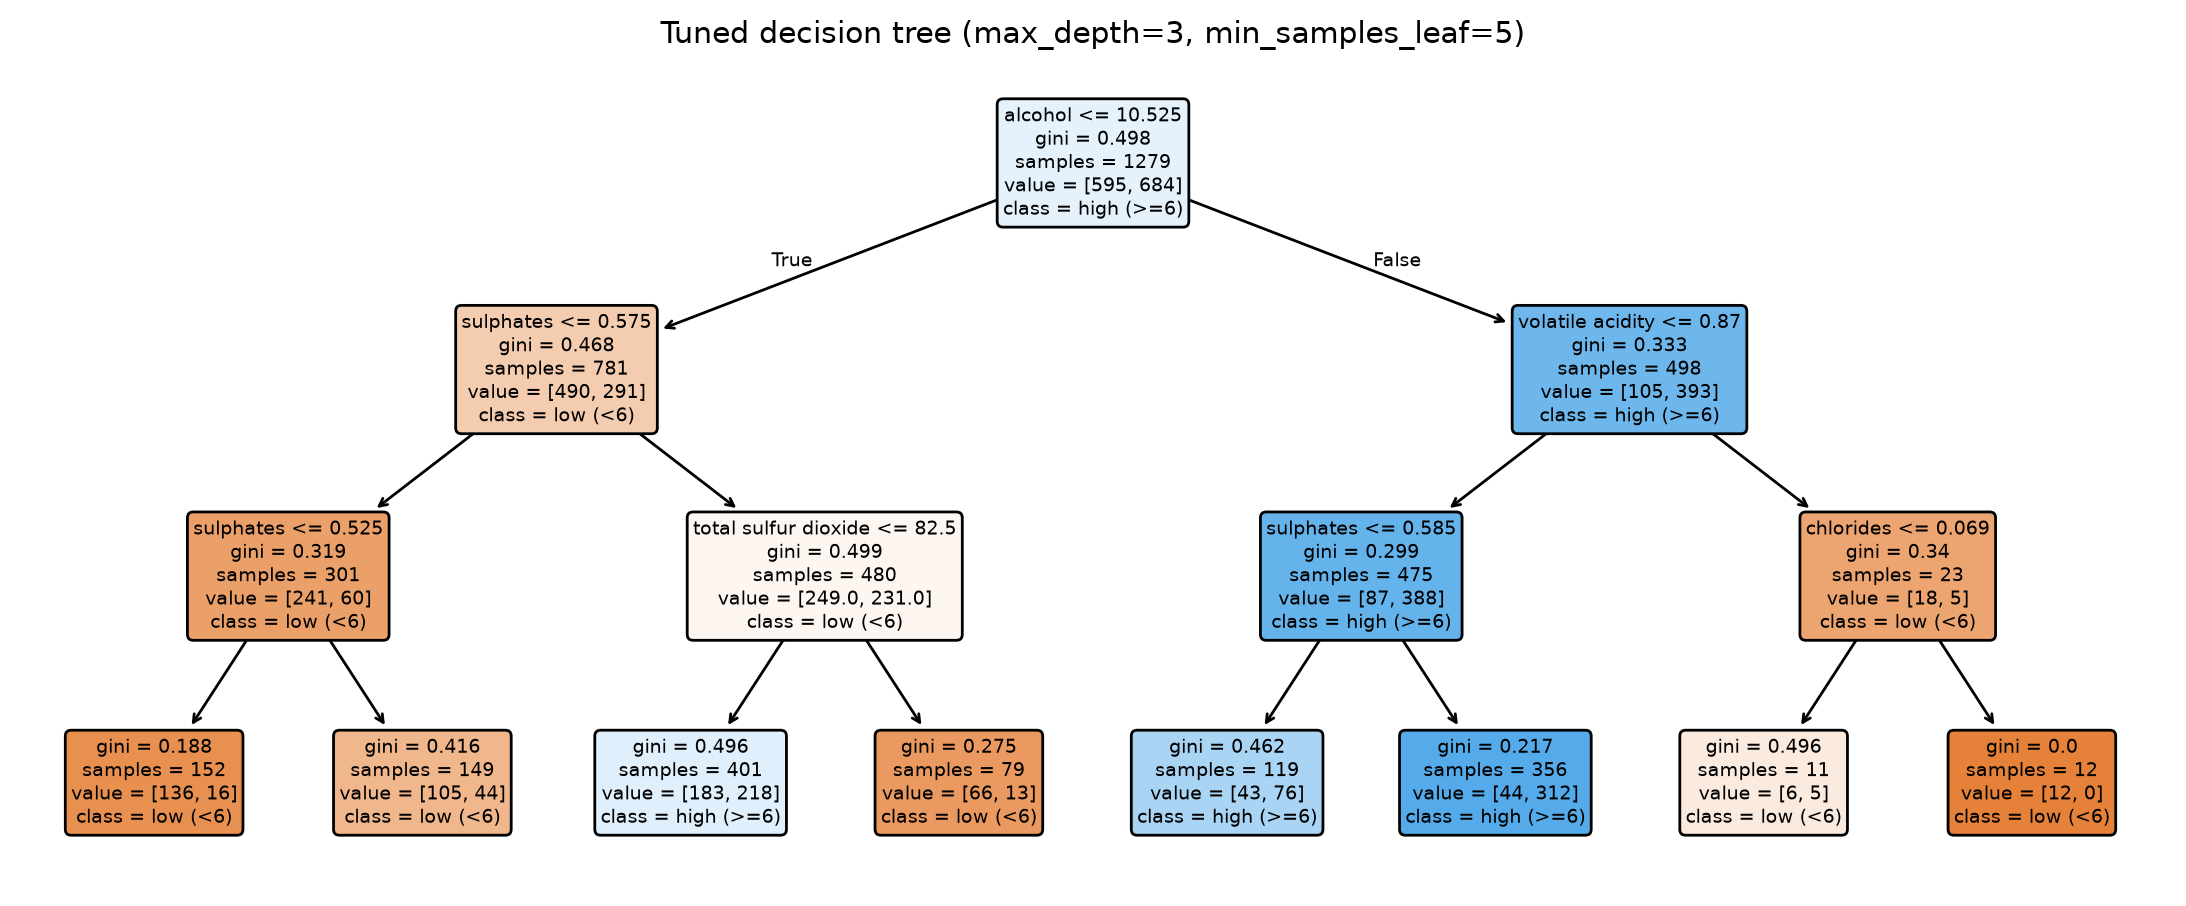

In [5]:
tuned = trees["Tuned (max_depth=3, min_samples_leaf=5)"]
fig, ax = plt.subplots(figsize=(11, 4.6))
plot_tree(tuned, feature_names=feature_names, class_names=["low (<6)", "high (>=6)"],
          filled=True, rounded=True, impurity=True, fontsize=7, ax=ax)
ax.set_title("Tuned decision tree (max_depth=3, min_samples_leaf=5)")
fig.tight_layout()
plt.show()

## Complete numeric results for reproducibility

In [6]:
print(json.dumps(results["task1"], sort_keys=True))

{"n_high": 855, "n_low": 744, "n_samples": 1599, "trees": {"Default (unconstrained)": {"depth": 18, "leaves": 209, "precision": 0.764367816091954, "recall": 0.7777777777777778, "test_acc": 0.753125, "train_acc": 1.0}, "Tuned (max_depth=3, min_samples_leaf=5)": {"depth": 3, "leaves": 8, "precision": 0.6878048780487804, "recall": 0.8245614035087719, "test_acc": 0.70625, "train_acc": 0.7279124315871774}}}
